In [11]:
import numpy as np
import pandas as pd

In [12]:
df=pd.read_csv('E:\machine_learning\placement.csv')

In [13]:
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [14]:
df.shape

(100, 4)

In [15]:
df=df.iloc[:,1:5]

In [16]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   cgpa       100 non-null    float64
 1   iq         100 non-null    float64
 2   placement  100 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 2.5 KB


# steps

1. Preprocess + EDA + Feature Selection
2. Extract input and output cols
3. Scale the Values
4. Train Test Split
5. Train the model
6. Evaluate the model/model selection
7. Deploy the model

In [18]:
import matplotlib.pyplot as plt

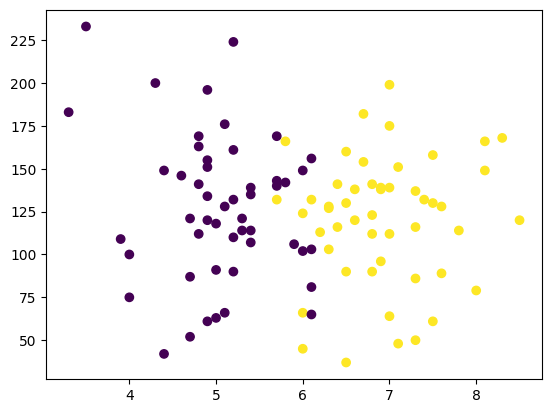

In [22]:
plt.scatter(df['cgpa'],df['iq'],c=df['placement'])

In [23]:
X=df.iloc[:,0:2]
y=df.iloc[:,-1]

In [24]:
X

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0
...,...,...
95,4.3,200.0
96,4.4,42.0
97,6.7,182.0
98,6.3,103.0


In [25]:
y

0     1
1     0
2     0
3     1
4     0
     ..
95    0
96    0
97    1
98    1
99    1
Name: placement, Length: 100, dtype: int64

In [26]:
y.shape

(100,)

In [28]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.1,random_state=0)

In [29]:
X_train

,cgpa,iq
53,8.3,168.0
92,5.2,110.0
78,6.1,81.0
13,6.4,116.0
7,5.0,63.0
...,...,...
96,4.4,42.0
67,5.0,118.0
64,7.0,64.0
47,5.2,161.0


In [30]:
y_train

53    1
92    0
78    0
13    1
7     0
     ..
96    0
67    0
64    1
47    0
44    1
Name: placement, Length: 90, dtype: int64

In [31]:
X_test

,cgpa,iq
26,7.0,199.0
86,5.1,128.0
2,5.3,121.0
55,7.8,114.0
75,4.8,169.0
93,6.8,112.0
16,5.2,224.0
73,4.9,61.0
54,6.4,141.0
95,4.3,200.0


In [32]:
y_test

26    1
86    0
2     0
55    1
75    0
93    1
16    0
73    0
54    1
95    0
Name: placement, dtype: int64

In [33]:
from sklearn.preprocessing import StandardScaler

In [34]:
scaler=StandardScaler()

In [36]:
X_train=scaler.fit_transform(X_train)

In [37]:
X_train

array([[ 2.00308668e+00,  1.24073424e+00],
       [-7.16432461e-01, -2.90022729e-01],
       [ 7.31053532e-02, -1.05540121e+00],
       [ 3.36284625e-01, -1.31668559e-01],
       [-8.91885309e-01, -1.53046372e+00],
       [ 1.38900171e+00,  1.85039779e-01],
       [-9.79611733e-01, -2.60991131e-02],
       [-1.15506458e+00,  2.93248462e-04],
       [-1.46210706e-02,  7.39279372e-01],
       [ 7.31053532e-02,  9.24025903e-01],
       [ 6.87190320e-01,  5.28140479e-01],
       [-1.46210706e-02, -5.01161621e-01],
       [ 1.21354886e+00,  2.90609225e-01],
       [ 7.31053532e-02,  2.90609225e-01],
       [-1.46210706e-02, -1.45128664e+00],
       [ 5.11737472e-01,  4.48963395e-01],
       [-2.77800342e-01,  5.80925202e-01],
       [ 1.60831777e-01, -2.10845644e-01],
       [ 4.24011048e-01, -2.21666512e+00],
       [-9.79611733e-01,  8.97633541e-01],
       [ 7.74916744e-01,  4.75355756e-01],
       [-9.79611733e-01,  1.97972036e+00],
       [ 1.12582244e+00, -9.23439406e-01],
       [-1.

In [38]:
X_test=scaler.transform(X_test)

In [39]:
X_test

array([[ 8.62643167e-01,  2.05889745e+00],
       [-8.04158885e-01,  1.85039779e-01],
       [-6.28706037e-01,  2.93248462e-04],
       [ 1.56445456e+00, -1.84453282e-01],
       [-1.06733816e+00,  1.26712660e+00],
       [ 6.87190320e-01, -2.37238005e-01],
       [-7.16432461e-01,  2.71870649e+00],
       [-9.79611733e-01, -1.58324844e+00],
       [ 3.36284625e-01,  5.28140479e-01],
       [-1.50597028e+00,  2.08528981e+00]])

In [40]:
from sklearn.linear_model import LogisticRegression

In [41]:
clf=LogisticRegression()

In [42]:
# model training

clf.fit(X_train,y_train)

LogisticRegression()

In [45]:
y_pred=clf.predict(X_test)

In [46]:
y_test

26    1
86    0
2     0
55    1
75    0
93    1
16    0
73    0
54    1
95    0
Name: placement, dtype: int64

In [47]:
from sklearn.metrics import accuracy_score

In [48]:
accuracy_score(y_test,y_pred)

1.0

In [49]:
from mlxtend.plotting import plot_decision_regions

<Axes: >

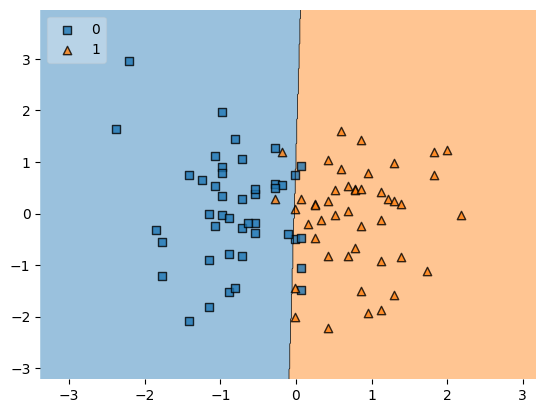

In [50]:
plot_decision_regions(X_train, y_train.values, clf=clf, legend=2)

In [51]:
import pickle


Caching the list of root modules, please wait!
(This will only be done once - type '%rehashx' to reset cache!)



C:\Users\Kshama\AppData\Roaming\Python\Python310\site-packages\IPython\core\completerlib.py:150: UserWarning: This is now an optional IPython functionality, setting rootmodules_cache requires you to install the `pickleshare` library.
  ip.db['rootmodules_cache'] = rootmodules_cache


In [52]:
pickle.dump(clf,open('model.pkl','wb'))